In [1]:
!pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable


In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

In [3]:
df = pd.read_csv(r"D:\ml-from-scratch\pima-predict\data\pima.csv")

In [4]:
df.shape

(768, 9)

In [5]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [6]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [7]:
y = df['Outcome'].to_numpy()
x = df.drop(['Outcome'], axis=1).to_numpy()

In [ ]:
features = list( df.drop(["Outcome"], axis=1).columns)
features

ValueError: Cannot specify both 'axis' and 'index'/'columns'

In [ ]:
x_1, x_test, y_1,y_test = train_test_split(x,y, test_size = 0.2, random_state=42)
x_train, x_val, y_train, y_val = train_test_split(x_1,y_1, test_size=0.25, random_state = 42)

In [ ]:
x_train.shape, x_test.shape, y_train.shape, y_test.shape

((460, 8), (154, 8), (460,), (154,))

In [ ]:
cols_zeros = [features.index(c) for c in
             ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]]


In [ ]:
moyenne = {}
for j in cols_zeros:
    moyenne[j] = x_train[x_train[:, j] != 0, j].mean()
    x_train[x_train[:,j]  == 0,j  ] = moyenne[j]
    x_test[x_test[:,j]  == 0,j  ] = moyenne[j]
    x_val[x_val[:,j]  == 0,j  ] = moyenne[j]

In [ ]:
moyenne

{1: 122.32307692307693,
 2: 72.49773755656109,
 3: 28.015290519877677,
 4: 159.7866108786611,
 5: 32.51008771929824}

#Standardisation

In [ ]:
train_mean = x_train.mean(axis=0)
train_std = x_train.std(axis=0)
x_train = (x_train - train_mean)/train_std 
x_test = (x_test - train_mean)/ train_std
x_val = (x_val - train_mean)/ train_std



In [ ]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

In [ ]:
w = np.zeros(8)  # Initialisation des poids pour huit caracteristiques
b = 0
lr = 0.05
nb_iteration = 10000
landa = 0.1
resultat = []
def train(X, y, w, b, lr, nb_iteration):
    for n in range(nb_iteration):
        z = X @ w + b
        y_pred = sigmoid(z)
        erreur = y_pred - y
        grad_w = (X.T @ erreur + 2*landa*w)/ len(y)  # Gradient pour les poids
        grad_b = np.mean(erreur)

        w -= lr * grad_w
        b -= lr * grad_b

    print("Poids w1:", w[0])
    print("Poids w2:", w[1])
    print("Biais:", b)
    z = X @ w + b
    y_pred = sigmoid(z)

    resultat = np.where(y_pred > 0.5, 1, 0)
    print("Predictions:", resultat)
    print("Exactitude:", np.mean(resultat == y))
    return w, b, resultat

In [ ]:
def accuracy(y,y_pred):
    return np.mean( y ==  y_pred)

In [ ]:
w,b,resultat = train(x_train, y_train, w, b, lr, nb_iteration)
w_final = w.copy()
b_final = b 
threshold  =0.3
predictions_params = {
   "threshold": threshold , "w" : w_final, "b" : b_final, "cols_zero": cols_zeros, "features" : features, "mean": train_mean,"std":train_std
}
import joblib 
joblib.dump(predictions_params,r"D:\ml-from-scratch\pima-predict\data\model.joblib")

NameError: name 'train' is not defined

In [ ]:
print(accuracy(y_train, resultat))

0.7478260869565218


In [ ]:
def test(X, w, b):        
    z = X @ w + b
    y_pred = sigmoid(z)
    return np.where(y_pred > 0.5, 1, 0)

predictions = test(x_test, w, b)
print(predictions.shape)
print("Exactitude sur le test:", accuracy(y_test, predictions))


(154,)
Exactitude sur le test: 0.7272727272727273


In [ ]:
learning_sizes = [10,30,100,250,459]
train_accs= []
val_accs= []
for i in learning_sizes:
    w=np.zeros(8)
    b=0
    lr = 0.5
    nb_iterations = 1000
    landa = 0.1
    x = x_train[:i,:]
    y = y_train[:i]
    w,b,results = train(x, y, w, b, lr, nb_iterations)
    train_accs.append((accuracy(y,results)))
    results = test(x_val,w,b)
    val_accs.append((accuracy(y_val,results)))



Poids w1: 1.730710935836411
Poids w2: 1.1860070503569293
Biais: -0.9677219177902994
Predictions: [0 0 0 1 0 0 1 0 0 0]
Exactitude: 0.9
Poids w1: 2.0641504334068483
Poids w2: 2.4339764710325267
Biais: -0.9280098501752183
Predictions: [0 0 0 1 0 1 1 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0]
Exactitude: 0.8666666666666667
Poids w1: 0.5554537325913297
Poids w2: 1.1187507771280618
Biais: -0.7825382826958226
Predictions: [1 0 0 1 0 0 1 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 1 0 1 1 0 0 0
 0 1 0 0 0 1 0 0 1 0 1 0 1 0 0 0 0 1 0 0 1 0 1 0 1 0 0 0 0 0 0 0 1 0 0 1 0
 0 1 0 0 0 0 0 0 1 1 0 0 0 0 0 1 0 1 1 0 0 0 0 0 0 1]
Exactitude: 0.79
Poids w1: 0.2789343115621025
Poids w2: 1.0187359852798215
Biais: -0.7610083885748831
Predictions: [1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 1 0 1 1 0 0 0
 0 1 0 0 0 1 0 0 0 0 1 0 1 0 1 0 0 1 0 0 1 0 0 0 1 1 0 0 0 0 0 0 1 0 0 1 0
 0 1 0 0 0 0 0 0 1 1 0 1 0 0 0 1 1 1 1 0 0 0 0 0 0 1 1 0 0 1 0 0 1 0 0 0 1
 1 0 0 0 1 1 1 0 0 1 0 0 0 0 0 0

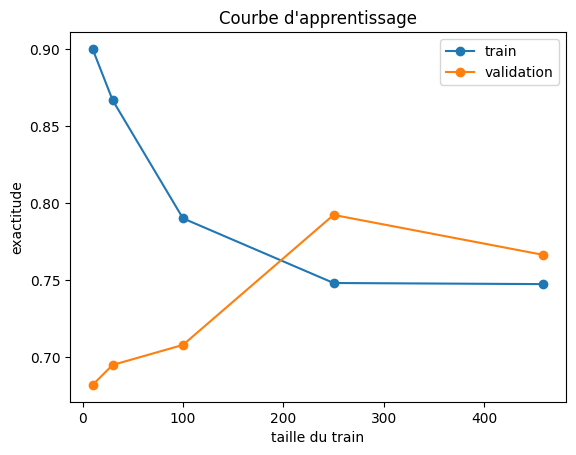

In [ ]:
import matplotlib.pyplot as plt

plt.plot(learning_sizes, train_accs, marker='o', label='train')
plt.plot(learning_sizes, val_accs, marker='o', label='validation')
plt.xlabel("taille du train")
plt.ylabel("exactitude")
plt.title("Courbe d'apprentissage")
plt.legend()
plt.show()

In [ ]:
thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]
def eval(X, w, b, threshold=0.5):        
    z = X @ w + b
    y_pred = sigmoid(z)
    return np.where(y_pred >threshold, 1, 0)
F1_accs=[] 
for i in thresholds:
    val_preds = eval(x_val, w,b,i )

    print("Exactitude sur le jeu de test:", accuracy(y_val, val_preds))
    
    VP = np.sum((val_preds == 1) & (y_val == 1))
    VN = np.sum((val_preds == 0) & (y_val == 0))
    FP = np.sum((val_preds == 1) & (y_val == 0))
    FN = np.sum((val_preds == 0) & (y_val == 1))
    print("VP:", VP)
    print("VN:", VN)     
    print("FP:", FP)
    print("FN:", FN)

    recall = VP/(VP+ FN)
    precision=VP/(VP+ FP)
    F1_score=2*(precision*recall)/(precision+recall)
    F1_accs.append(F1_score) 

Exactitude sur le jeu de test: 0.7597402597402597
VP: 41
VN: 76
FP: 25
FN: 12
Exactitude sur le jeu de test: 0.7922077922077922
VP: 34
VN: 88
FP: 13
FN: 19
Exactitude sur le jeu de test: 0.7662337662337663
VP: 26
VN: 92
FP: 9
FN: 27
Exactitude sur le jeu de test: 0.7402597402597403
VP: 19
VN: 95
FP: 6
FN: 34
Exactitude sur le jeu de test: 0.7337662337662337
VP: 16
VN: 97
FP: 4
FN: 37


In [ ]:
F1_accs

[0.689075630252101,
 0.68,
 0.5909090909090909,
 0.48717948717948717,
 0.4383561643835617]

In [ ]:
test_preds = eval(x_test, w,b,0.3 )
print("Exactitude sur le jeu de test:", accuracy(y_test, test_preds))
VP = np.sum((test_preds == 1) & (y_test == 1))
VN = np.sum((test_preds == 0) & (y_test == 0))
FP = np.sum((test_preds == 1) & (y_test == 0))
FN = np.sum((test_preds == 0) & (y_test == 1))
recall = VP/(VP+ FN)
precision=VP/(VP+ FP)
F1_score=2*(precision*recall)/(precision+recall)
print(F1_score)

Exactitude sur le jeu de test: 0.7077922077922078
0.6511627906976745
